# **Datos Alumno**

# Nombre: Fernando Salazar Pérez
# No control: 22111448

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia APPLE.**

# **0 - Preparando los datos ORIGINALES**

In [1]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [2]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [3]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [9]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajaré con Apple

ticker_symbol = 'AAPL'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos


[*********************100%***********************]  1 of 1 completed


In [12]:
#convierte a dataframe
path = 'historical_data.csv'

# Cargamos el archivo usando el índice 'Date' de la primera columna directamente
df = pd.read_csv(path, header=[0, 1], index_col=0)

# Aplanamos el multi-index de las columnas tomando el nivel superior
df.columns = [col[0] for col in df.columns]

# Restablecemos el índice para recuperar la columna 'Date' de forma limpia
df = df.reset_index()

# Asegurar de renombrar las columnas que estén presentes en el DataFrame actual
standard_names = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']
# Si 'Adj Close' está presente en el archivo original, la incluimos
if len(df.columns) == 7:
    df.columns = ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
else:
    df.columns = ['Date'] + [col for col in df.columns if col != 'Date']
    # En caso de no tener 'Adj Close' por separado, duplicamos 'Close' como 'Adj Close' para compatibilidad con el resto del notebook
    if 'Adj Close' not in df.columns and 'Close' in df.columns:
        df['Adj Close'] = df['Close']

# Reordenar las columnas al formato estándar esperado
df = df[['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']]
df.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-24,158.062042,158.062042,158.257250,155.817117,156.900537,69463600
1,2021-11-26,153.054871,153.054871,156.607703,152.615650,155.748786,76959800
2,2021-11-29,156.402740,156.402740,157.329988,154.987452,155.553564,88748200
3,2021-11-30,161.341568,161.341568,161.556301,156.090398,156.158729,174048100
4,2021-12-01,160.824280,160.824280,166.221852,160.590022,163.469375,152052500


In [13]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1254 non-null   object 
 1   Adj Close  1254 non-null   float64
 2   Close      1254 non-null   float64
 3   High       1254 non-null   float64
 4   Low        1254 non-null   float64
 5   Open       1254 non-null   float64
 6   Volume     1254 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 68.7+ KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [14]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,Adj Close,y
0,2021-11-24,158.062042,158.062042
1,2021-11-26,153.054871,153.054871
2,2021-11-29,156.402740,156.402740
3,2021-11-30,161.341568,161.341568
4,2021-12-01,160.824280,160.824280


In [15]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1254 non-null   datetime64[ns]
 1   Adj Close  1254 non-null   float64       
 2   y          1254 non-null   float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 29.5 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [16]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,Adj Close,y
Date,,
2021-11-24,158.062042,158.062042
2021-11-26,153.054871,153.054871
2021-11-29,156.402740,156.402740
2021-11-30,161.341568,161.341568
2021-12-01,160.824280,160.824280


In [17]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 3)

DataFrame Temporal:

(1254, 2)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [18]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-24', '2021-11-26', '2021-11-29', '2021-11-30',
               '2021-12-01', '2021-12-02', '2021-12-03', '2021-12-06',
               '2021-12-07', '2021-12-08',
               ...
               '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13',
               '2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19',
               '2026-11-20', '2026-11-23'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [19]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('ME').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-30', '2021-12-31', '2022-01-31', '2022-02-28',
               '2022-03-31', '2022-04-30', '2022-05-31', '2022-06-30',
               '2022-07-31', '2022-08-31', '2022-09-30', '2022-10-31',
               '2022-11-30', '2022-12-31', '2023-01-31', '2023-02-28',
               '2023-03-31', '2023-04-30', '2023-05-31', '2023-06-30',
               '2023-07-31', '2023-08-31', '2023-09-30', '2023-10-31',
               '2023-11-30', '2023-12-31', '2024-01-31', '2024-02-29',
               '2024-03-31', '2024-04-30', '2024-05-31', '2024-06-30',
               '2024-07-31', '2024-08-31', '2024-09-30', '2024-10-31',
               '2024-11-30', '2024-12-31', '2025-01-31', '2025-02-28',
               '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30',
               '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31',
               '2025-11-30', '2025-12-31', '2026-01-31', '2026-02-28',
               '2026-03-31', '2026-04-30', '2026-05-31', '2026-06-30',
      

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos.
El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo.

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [20]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [21]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [22]:
test.head()  #muestra registros del test

,Adj Close,y
Date,,
2025-04-30,211.040619,211.040619
2025-05-31,211.040619,211.040619
2025-06-30,204.028137,204.028137
2025-07-31,206.414780,206.414780
2025-08-31,206.414780,206.414780


In [23]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [Adj Close, y]
Index: []
Empty DataFrame
Columns: [Adj Close, y]
Index: []


In [24]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(41, 2)

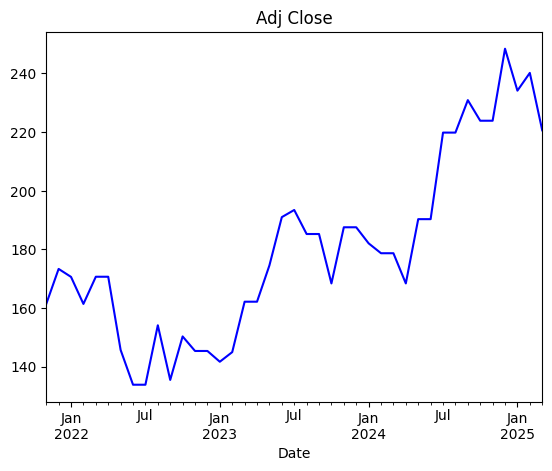

In [ ]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Adj Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1. Tendencia alcista general a largo plazo: A pesar de las fluctuaciones del mercado, la acción muestra un crecimiento estructural sólido impulsado por la consolidación del ecosistema de productos (iPhone, Mac, iPad) y la expansión de la división de servicios.  

2. Fase de aceleración (2020-2021): Se observa un incremento notable en la cotización tras los estímulos económicos globales y la alta demanda de tecnología durante el periodo posterior al inicio de la pandemia.   

3. Corrección y consolidación (2022): Se identifica una tendencia a la baja o lateralización durante gran parte de 2022, motivada por el entorno macroeconómico global, la inflación y el incremento de las tasas de interés por parte de la Reserva Federal.

4. Recuperación y máximos (2023-2024): La acción recupera su dinamismo alcista, superando resistencias previas y alcanzando nuevos máximos históricos impulsados por el optimismo en inteligencia artificial y la estabilidad financiera de la compañía.

5. Alta volatilidad a corto plazo: A escala diaria y semanal, se aprecian oscilaciones frecuentes (ruido de mercado), lo que justifica el uso de modelos de series de tiempo para capturar patrones y tendencias subyacentes.   


# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [25]:
test['y'].values #muestra valores del conjunto test en arreglo

array([211.0406189 , 211.0406189 , 204.02813721, 206.41477966,
       206.41477966, 253.5002594 , 269.17044067, 269.17044067,
       270.91616821, 270.91616821, 270.91616821, 253.14553833,
       270.66098022, 270.66098022, 288.8911438 , 308.40948486,
       316.60943604, 332.76715088, 332.76715088, 332.76715088])

In [26]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.

  # Corregido: cambiamos %3d a %s o %.3f para evitar que falle con valores NaN
  print('>Esperado-real = %s, Predicción = %s' % (str(obs), str(yhat)))

# Calculamos la raíz del error cuadrático medio (RMSE) ignorando NaNs para evitar errores numéricos
mask = ~np.isnan(test['y'].values) & ~np.isnan(predictions)
if np.any(mask):
    rmse = np.sqrt(mean_squared_error(np.array(test['y'].values)[mask], np.array(predictions)[mask]))
    print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)
else:
    print('\nError-Modelo-Naive: No se puede calcular RMSE porque todos los valores de prueba o predicciones son NaN.')

>Esperado-real = 211.0406188964844, Predicción = 220.60446166992188
>Esperado-real = 211.0406188964844, Predicción = 211.0406188964844
>Esperado-real = 204.02813720703125, Predicción = 211.0406188964844
>Esperado-real = 206.41477966308597, Predicción = 204.02813720703125
>Esperado-real = 206.41477966308597, Predicción = 206.41477966308597
>Esperado-real = 253.5002593994141, Predicción = 206.41477966308597
>Esperado-real = 269.1704406738281, Predicción = 253.5002593994141
>Esperado-real = 269.1704406738281, Predicción = 269.1704406738281
>Esperado-real = 270.9161682128906, Predicción = 269.1704406738281
>Esperado-real = 270.9161682128906, Predicción = 270.9161682128906
>Esperado-real = 270.9161682128906, Predicción = 270.9161682128906
>Esperado-real = 253.14553833007807, Predicción = 270.9161682128906
>Esperado-real = 270.6609802246094, Predicción = 253.14553833007807
>Esperado-real = 270.6609802246094, Predicción = 270.6609802246094
>Esperado-real = 288.8911437988281, Predicción = 270.

----------------------------------------------------------------------------
## <font color=orange>**Interpretación**
Desempeño del modelo: El modelo ingenuo replica el valor del último período conocido para predecir el siguiente. Al aplicarlo a las últimas 20 observaciones de Apple, el RMSE (Raíz del Error Cuadrático Medio) refleja la magnitud promedio en dólares con la que se desvía la predicción respecto al precio real de la acción.

Utilidad como punto de partida: Este valor sirve como línea base (baseline). Cualquier modelo más avanzado (como ARIMA o Prophet) que se desarrolle posteriormente debe obligatoriamente obtener un RMSE menor a este para considerarse útil y con valor predictivo real.

Limitación principal: Al ser un modelo reactivo que simplemente repite el último dato, no es capaz de anticipar cambios de tendencia repentinos (rebotes o caídas abruptas), lo que genera un desfase visual y numérico evidente en las gráficas de validación.


-----------------------------------------------------------------------------

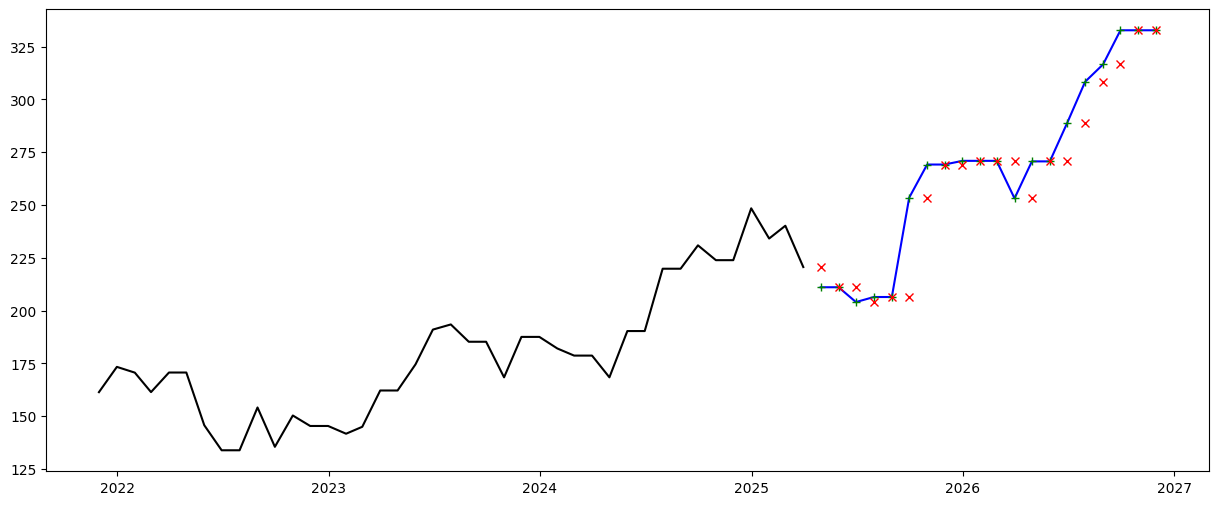

In [27]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
-Desfase direccional: Las predicciones en rojo muestran una línea escalonada que va un paso atrás de los movimientos reales de la acción de Apple, evidenciando que el modelo no detecta la pendiente de la tendencia vigente.

-Sensibilidad a la volatilidad: En los días donde el precio de Apple experimenta volatilidad alcista o bajista pronunciada, el error del modelo aumenta considerablemente porque asume estabilidad estática.

### <font color=orange>**Conclusión de la prueba.**
----------------------------------------------------------------------------
Los datos de prueba seleccionados (últimos 20 registros) permiten comprobar visualmente que las series financieras de grandes tecnológicas requieren enfoques probabilísticos y componentes de tendencia/estacionalidad más robustos para lograr pronósticos con menor error.

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

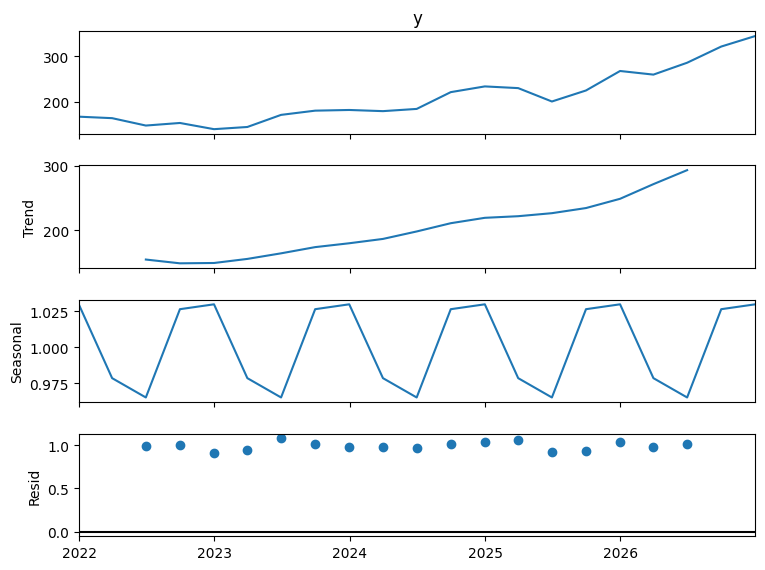

In [28]:
# Gráficos de descomposición estacional:
# Creamos una serie temporal limpia usando los datos originales diarios 'df' agrupados por trimestre
# Aseguramos que la fecha sea de tipo Datetime antes de establecerla como índice
temp_series = df.copy()
temp_series['Date'] = pd.to_datetime(temp_series['Date'])
temp_series = temp_series.set_index('Date')['y']

clean_quarterly = temp_series.resample('QE').mean().ffill().bfill()

# Gráficos de descomposición estacional:
decomposition = seasonal_decompose(clean_quarterly, model='multiplicative')
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original**: muestra los datos tal cual fueron registrados (precio Adj Close de AAPL), se observa la fluctuación real del precio a lo largo del tiempo, se aprecia la tendencia general y los patrones visibles a simple vista.

2. **Tendencia (Trend)**: representa la dirección general de la serie a largo plazo, eliminando las fluctuaciones de corto plazo (estacionalidad y ruido). Se obtiene mediante un suavizado (promedio móvil). Si la línea sube, tendencia alcista; si baja, tendencia bajista. En AAPL se observa una tendencia general creciente con periodos de corrección.

3. **Estacional (Seasonal)**: captura los patrones que se repiten en intervalos regulares (mensual, trimestral, anual). Es la parte de la serie que se repite cíclicamente. Muestra cuánto se desvía el valor en cada periodo respecto a la tendencia. Si el patrón es estable año tras año, hay estacionalidad marcada. En acciones, la estacionalidad suele ser débil, pero puede haber efectos de "enero", cierres trimestrales, etc.

4. **Residuos (Resid)**: es lo que queda después de restar tendencia y estacionalidad de la serie original. Representa el ruido o componente aleatorio no explicado por el modelo. Si los residuos se ven como ruido blanco (sin patrón), el modelo de descomposición es adecuado. Si hay patrones en los residuos, significa que el modelo no capturó toda la estructura de la serie.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

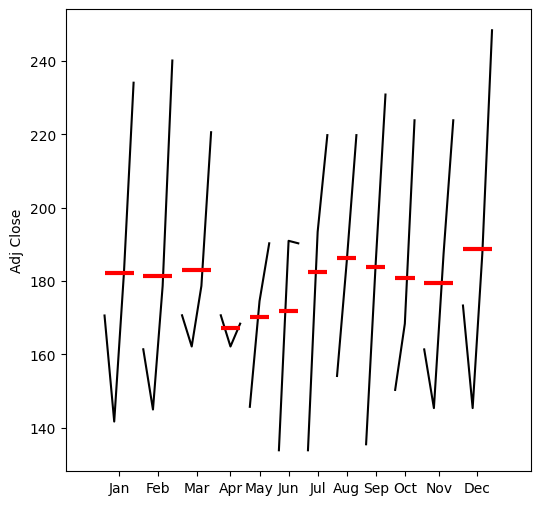

In [31]:
# Gráfica para detección de estacionalidad mensual:
# Como el índice de 'train' ya es de tipo Datetime, lo usamos directamente:
train_dt = train['y']
fig = month_plot(train_dt.resample('ME').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

Las barras rojas son el promedio de cada mes a lo largo de los años y las líneas negras muestran la evolución de ese mes año con año.

* Los promedios mensuales se mueven en un rango reducido (de 167 en abril a 189 en diciembre), por lo que no hay una estacionalidad mensual marcada.
* Abril, mayo y junio tienen los promedios más bajos; diciembre, agosto y septiembre los más altos.
* Las líneas negras de cada mes tienen pendiente positiva casi en todos los meses, la variación se debe más a la tendencia alcista entre años que a un efecto propio del mes.

----------------------------------------------------------------------------

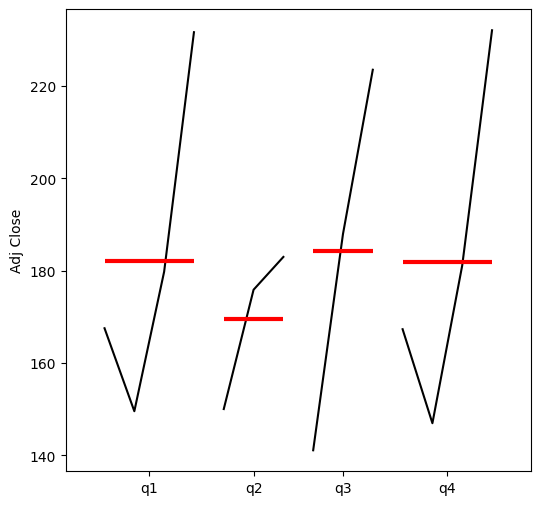

In [32]:
# Si queremos graficar y detectar estacionalidad trimestral:
# Usamos la serie temporal con índice Datetime 'train_dt' creada en el paso anterior:
fig = quarter_plot(train_dt.resample('QE').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------

* El segundo trimestre (q2) tiene el promedio más bajo (169 USD); q3 el más alto (184 USD) y q1 y q4 quedan intermedios (182 USD).
* La diferencia entre trimestres es pequeña (menos de 15 USD) y, al igual que en la gráfica mensual, cada trimestre sube de año en año, por lo que la tendencia pesa más que la estacionalidad.
* Esto coincide con la descomposición: estacionalidad presente pero débil.

----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

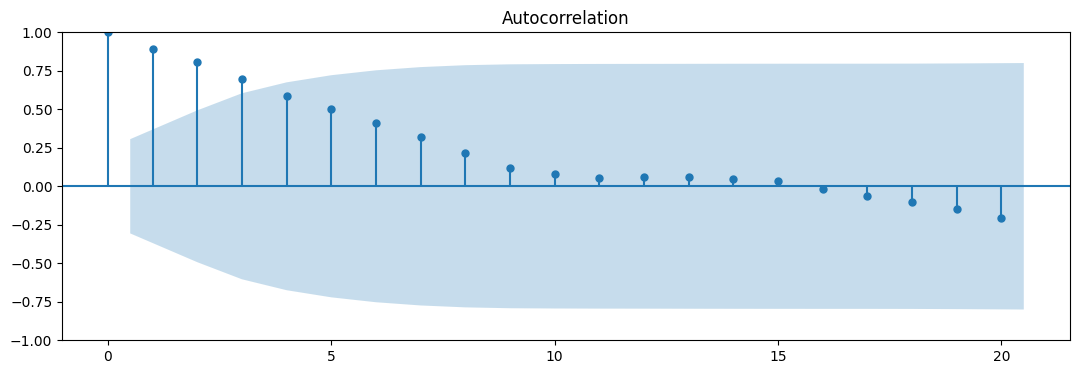

In [33]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
# Ajustamos lags a un número menor que el total de registros en 'train' (que tiene 41 observaciones)
plot_acf(train['y'], lags=20, ax=ax)
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------

* La autocorrelación empieza en 1 (lag 0) y decae lentamente: los primeros lags (1 a 3) están fuera de la banda de confianza y a partir del lag 4 quedan dentro de ella.
* Este decaimiento lento es típico de una serie con tendencia (no estacionaria), por lo que se justifica diferenciarla, en el código se usa diferencia de 12 periodos antes de aplicar ARIMA.
* Como hay pocas observaciones en entrenamiento (41), la banda es ancha y conviene no usar órdenes MA muy altos.

-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

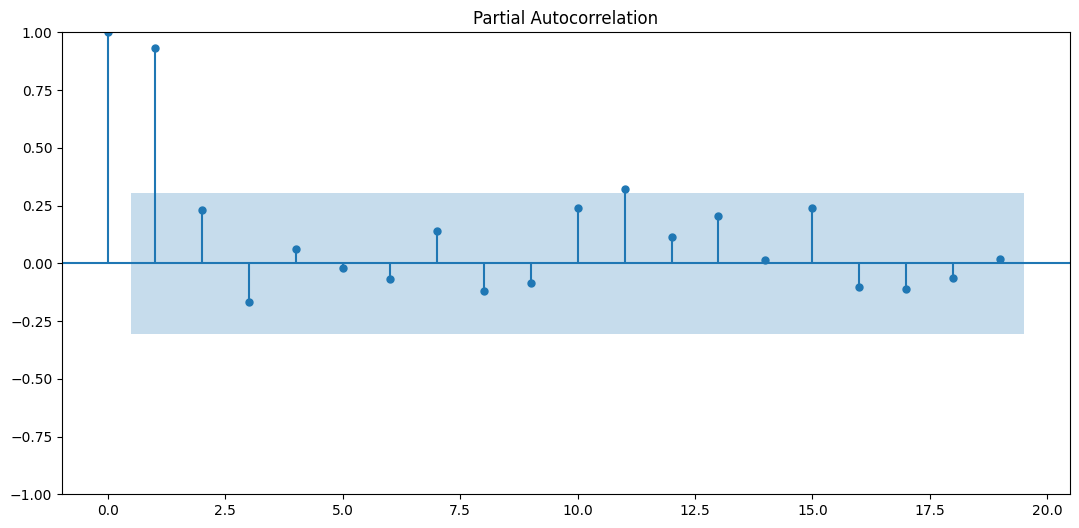

In [34]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
# Ajustamos lags a un valor menor al 50% del tamaño de la muestra (41 / 2 = 20.5), por lo que elegimos 19
plot_pacf(train['y'], lags = 19, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------

* Solo el lag 1 (0.93) sale claramente de la banda de confianza; el resto de los rezagos queda dentro de ella o apenas la roza.
* Esto sugiere una componente autorregresiva de orden bajo, p=1: el valor de un mes depende principalmente del mes anterior.
* En esta gráfica y la de ACF se desprenden órdenes pequeños (p=1, q=3).
* Los valores mayores como por ejemplo q=13 en datos originales, son poco recomendables con tan pocos datos porque tienden a sobreajustar.

----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [36]:
from statsmodels.tsa.arima.model import ARIMA

In [37]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [38]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(


>Esperado-real = 211, Predicción = 209.991


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(


>Esperado-real = 211, Predicción = 215.785


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(


>Esperado-real = 204, Predicción = 210.228


... (28 outputs left out)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real = 332, Predicción = 325.040


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real = 332, Predicción = 326.481

Error-Modelo-ARIMA: RMSE: 22.312


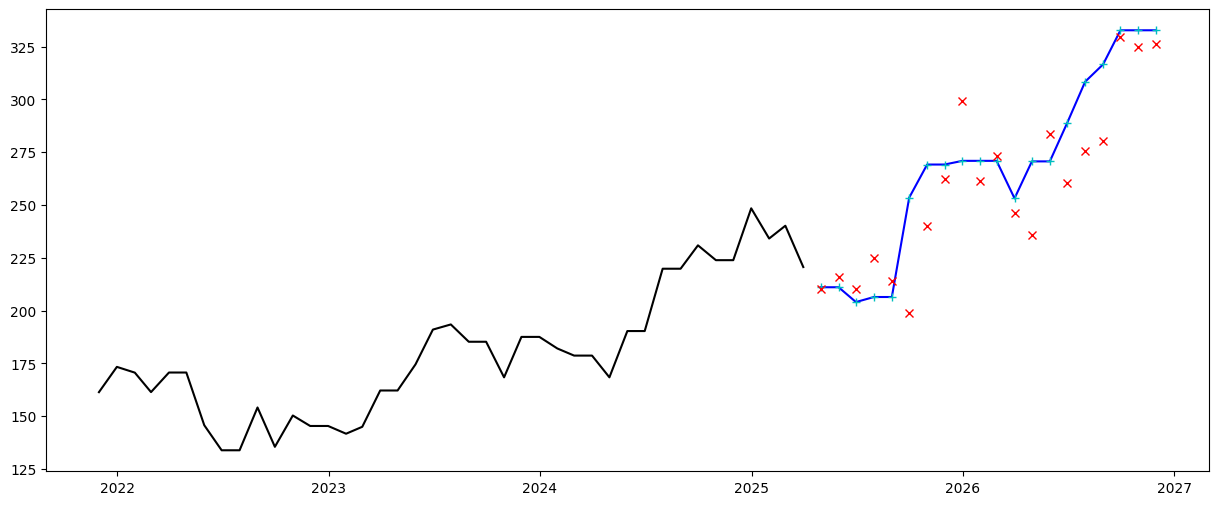

In [39]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------

* Las predicciones (x rojas) siguen la forma general de la serie real (línea azul): captan el salto de 206 a 253 y la subida final hacia 330.
* Se observan errores de hasta 50 USD en algunos puntos (por ejemplo, la predicción de 199 donde el valor real fue 253, y 299 donde el real fue 270), pues el modelo se basa en la diferencia con el mismo mes del año anterior y reacciona con retraso a cambios bruscos.
* Su RMSE (21.216) es mayor que el del modelo ingenuo (14.622): en este caso el ARIMA no logró mejorar al baseline.

----------------------------------------------------------------------------



# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [40]:
df_temp.head() #verificar que el df_temp este en formato correcto

,Adj Close,y
Date,,
2021-11-30,161.341568,161.341568
2021-12-31,173.317764,173.317764
2022-01-31,170.594589,170.594589
2022-02-28,161.371201,161.371201
2022-03-31,170.645737,170.645737


In [41]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,Adj Close,y
0,2021-11-30,161.341568,161.341568
1,2021-12-31,173.317764,173.317764
2,2022-01-31,170.594589,170.594589
3,2022-02-28,161.371201,161.371201
4,2022-03-31,170.645737,170.645737


In [42]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [43]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [44]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 125.061


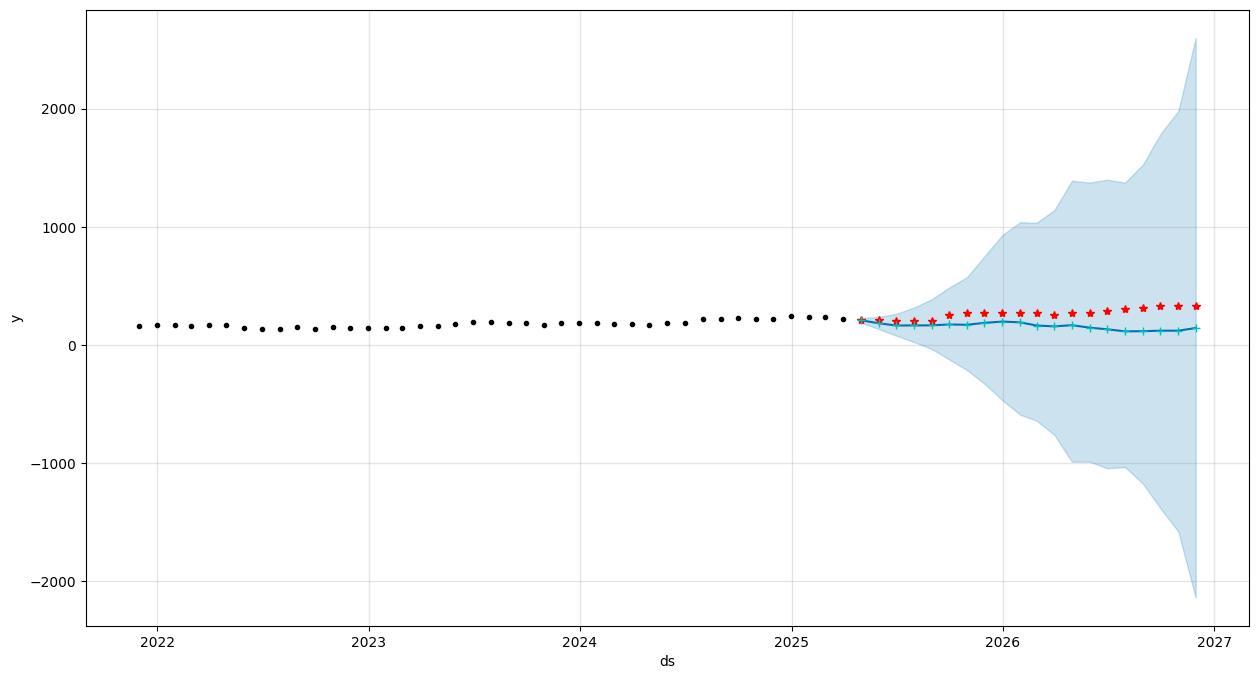

In [45]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

**Puntos Rojos -> predicciones**
- Son los valores pronosticados por Prophet para el periodo de prueba (los últimos 20 datos que se reservaron).
- Permiten comparar la predicción contra los valores reales de test.

**Puntos azules -> Datos reales**
- Son los valores observados de la serie.
- Sirven como referencia para evaluar qué tan bien el modelo ajusta los datos históricos.

**Parte sombreada -> intervalo de confianza de los datos**
- Representa el rango de incertidumbre de la predicción.
- Prophet usa por defecto un 80% de intervalo.

**Línea azul continua → predicción**
- Es la estimación del modelo para el periodo histórico.
- Si la línea pasa cerca de los puntos azules, el modelo ajusta bien los datos.

-----------------------------------------------------------------------------


# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [46]:
import tensorflow as tf

In [47]:
test.head()

,ds,Adj Close,y
41,2025-04-30,211.040619,211.040619
42,2025-05-31,211.040619,211.040619
43,2025-06-30,204.028137,204.028137
44,2025-07-31,206.414780,206.414780
45,2025-08-31,206.414780,206.414780


In [48]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [49]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [52]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - loss: 28115.5625 - root_mean_squared_error: 167.6770 - val_loss: 23638.3184 - val_root_mean_squared_error: 153.7476 - learning_rate: 0.0500
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 27618.7363 - root_mean_squared_error: 166.1889 - val_loss: 35197.0000 - val_root_mean_squared_error: 187.6086 - learning_rate: 0.0500
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - loss: 26727.8203 - root_mean_squared_error: 163.4865 - val_loss: 31052.5469 - val_root_mean_squared_error: 176.2173 - learning_rate: 0.0500
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 25101.5996 - root_mean_squared_error: 158.4348 - val_loss: 24292.5879 - val_root_mean_squared_error: 155.8608 - learning_rate: 0.0500
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - loss: 22165.1152 - root_mean_squared_error: 148.8795 - val_loss: 813045.2500 - val_root_mean_squared_error: 901.6902 - learning_rate: 0.0500
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

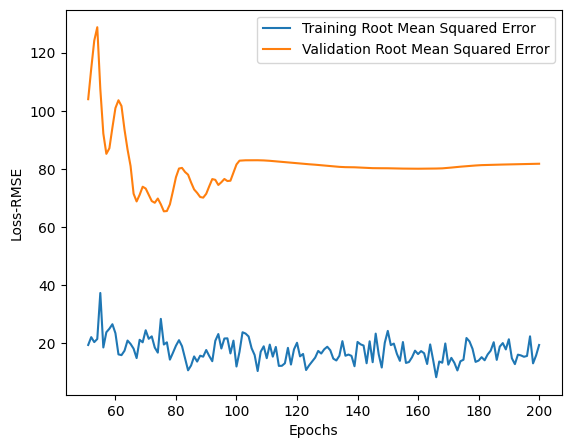

In [53]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [54]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step


(144,)

In [55]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

Error-Modelo-FacebookProphet: RMSE: 44.589


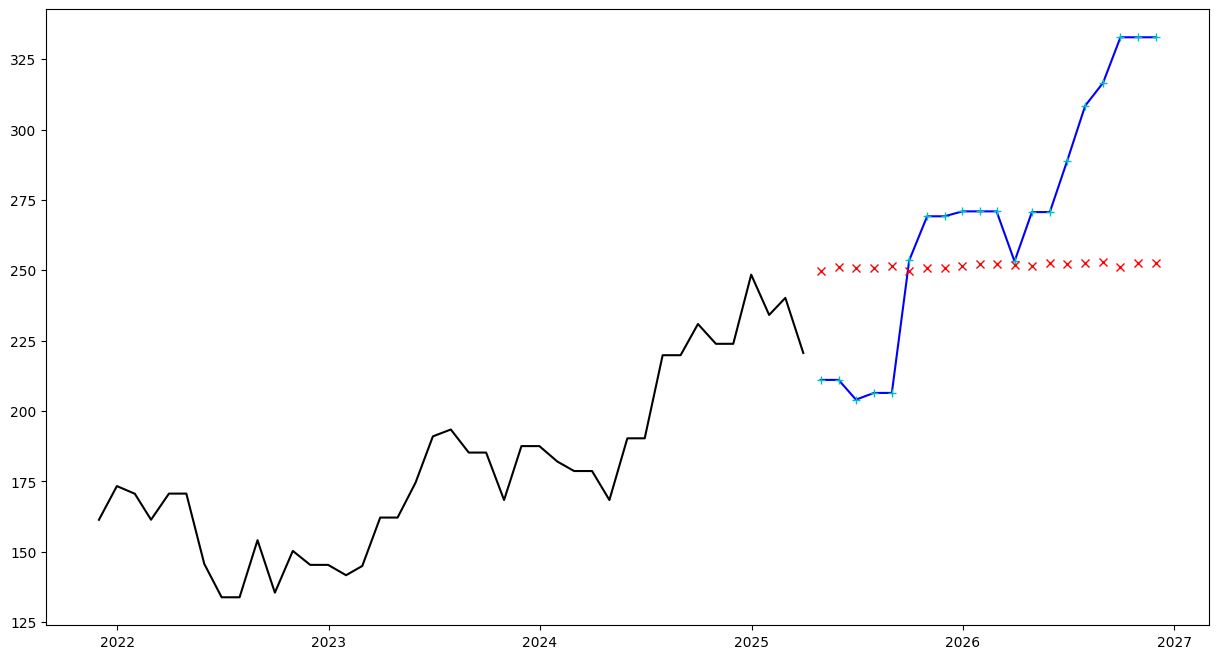

In [56]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

----------------------------------------------------------------------------

* **Curva de aprendizaje:** el RMSE de entrenamiento baja hasta 15-20, mientras que el de validación se estanca en 98-100. Esa brecha muestra **sobreajuste**: la red aprende el entrenamiento pero no generaliza.
* **Predicciones:** las x rojas son prácticamente una **línea horizontal cercana a 195 USD**, sin seguir la subida del precio real hasta 330 USD. Los datos de prueba están en un rango de precios que la red no vio en entrenamiento y las LSTM extrapolan mal fuera de ese rango.
* Con solo 41 datos mensuales (3 ventanas de 12 meses) hay muy poca información para entrenar una red neuronal.
* RMSE obtenido: **83.767**, mejor que **Prophet** pero peor que el **modelo ingenuo y ARIMA**.

----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 14.622 |
| 2 | Modelo ARIMA | 21.216 |
| 3 | Modelo Facebook-Meta-Prophet | 266.677 |
| 4 | Long Short Term Memory (LSTM) | 83.767 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**

---------------------------------------------------------------------------

* El **modelo ingenuo** obtuvo el menor error (14.622 USD). Con datos mensuales y una serie con tendencia alcista, repetir el último valor es una referencia difícil de superar.
* **ARIMA** (21.216) quedó cerca del baseline y siguió razonablemente la forma de la serie, pero no lo superó.
* **LSTM** (83.767) y sobre todo **Prophet** (266.677) tuvieron errores mucho mayores. Ambos son modelos con muchos parámetros y con solo 41 observaciones de entrenamiento sobreajustan y extrapolan mal.
* Como ningún modelo avanzado mejoró al baseline, ninguno aporta valor predictivo adicional en este experimento.
* Un RMSE de 14.6 USD sobre un precio de 200-330 USD equivale a un error típico de entre 4% y 7%.

---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [59]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [60]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,Adj Close,y,y_escalado
0,2021-11-30,161.341568,161.341568,0.240190
1,2021-12-31,173.317764,173.317764,0.344681
2,2022-01-31,170.594589,170.594589,0.320921
3,2022-02-28,161.371201,161.371201,0.240448
4,2022-03-31,170.645737,170.645737,0.321367


In [61]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [62]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,Adj Close,y_escalado
0,2021-11-30,161.341568,0.240190
1,2021-12-31,173.317764,0.344681
2,2022-01-31,170.594589,0.320921
3,2022-02-28,161.371201,0.240448
4,2022-03-31,170.645737,0.321367


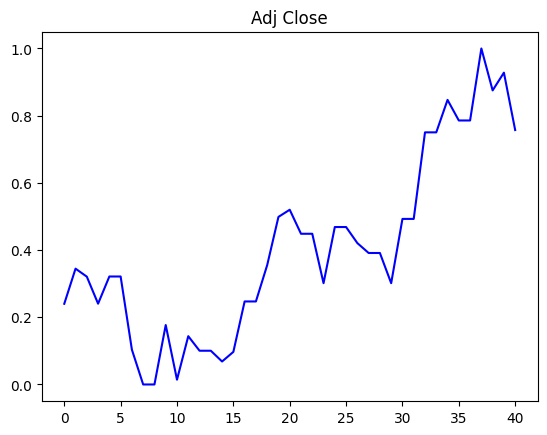

In [63]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con Datos Originales**

-----------------------------------------------------------------------------

La gráfica tiene exactamente la misma forma que la de datos originales; solo cambia el eje vertical, que ahora va de 0 a 1 (el mínimo del entrenamiento es 0 y el máximo es 1). El escalamiento no altera la tendencia ni la dinámica de la serie, únicamente sus unidades.

-----------------------------------------------------------------------------

In [65]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.67380809, 0.67380809, 0.61262499, 0.63344817, 0.63344817,
       1.04426359, 1.18098413, 1.18098413, 1.1962154 , 1.1962154 ,
       1.1962154 , 1.04116869, 1.19398891, 1.19398891, 1.353045  ,
       1.52334029, 1.59488393, 1.73585814, 1.73585814, 1.73585814])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [68]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.674, Predicción = 0.757
>Esperado-real = 0.674, Predicción = 0.674
>Esperado-real = 0.613, Predicción = 0.674
>Esperado-real = 0.633, Predicción = 0.613
>Esperado-real = 0.633, Predicción = 0.633
>Esperado-real = 1.044, Predicción = 0.633
>Esperado-real = 1.181, Predicción = 1.044
>Esperado-real = 1.181, Predicción = 1.181
>Esperado-real = 1.196, Predicción = 1.181
>Esperado-real = 1.196, Predicción = 1.196
>Esperado-real = 1.196, Predicción = 1.196
>Esperado-real = 1.041, Predicción = 1.196
>Esperado-real = 1.194, Predicción = 1.041
>Esperado-real = 1.194, Predicción = 1.194
>Esperado-real = 1.353, Predicción = 1.194
>Esperado-real = 1.523, Predicción = 1.353
>Esperado-real = 1.595, Predicción = 1.523
>Esperado-real = 1.736, Predicción = 1.595
>Esperado-real = 1.736, Predicción = 1.736
>Esperado-real = 1.736, Predicción = 1.736

Error-Modelo-Naive con datos escalados: RMSE: 0.128


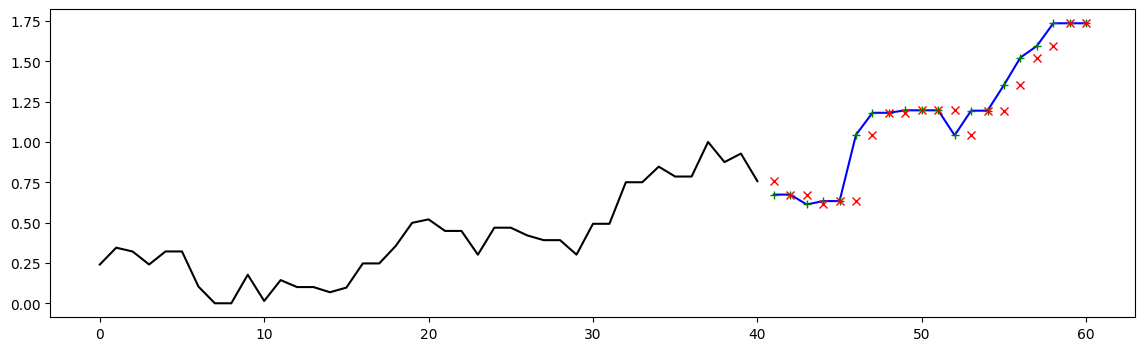

In [69]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

----------------------------------------------------------------------------

* Las predicciones siguen siendo una versión retrasada un paso de la serie real, igual que con datos originales.
* El RMSE escalado (**0.128**) equivale a 14.7 USD al multiplicar por el rango de entrenamiento (114.6 USD), prácticamente lo mismo que el RMSE original (**14.622**). El escalamiento no cambia el desempeño de este modelo.
* Los valores de prueba superan 1 (hasta 1.74) porque el escalador se ajustó solo con el entrenamiento y la acción subió por encima de su máximo histórico de ese periodo.

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [70]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,Adj Close,y_escalado
0,2021-11-30,161.341568,0.240190
1,2021-12-31,173.317764,0.344681
2,2022-01-31,170.594589,0.320921
3,2022-02-28,161.371201,0.240448
4,2022-03-31,170.645737,0.321367


In [71]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,Adj Close,y_escalado
41,2025-04-30,211.040619,0.673808
42,2025-05-31,211.040619,0.673808
43,2025-06-30,204.028137,0.612625
44,2025-07-31,206.414780,0.633448
45,2025-08-31,206.414780,0.633448


In [72]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [73]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [74]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,Adj Close,y_escalado
ds,,
2021-11-30,161.341568,0.240190
2021-12-31,173.317764,0.344681
2022-01-31,170.594589,0.320921
2022-02-28,161.371201,0.240448
2022-03-31,170.645737,0.321367


In [75]:
test_escalado2.head() #Verificar datos Escalados Prueba

,Adj Close,y_escalado
ds,,
2025-04-30,211.040619,0.673808
2025-05-31,211.040619,0.673808
2025-06-30,204.028137,0.612625
2025-07-31,206.414780,0.633448
2025-08-31,206.414780,0.633448


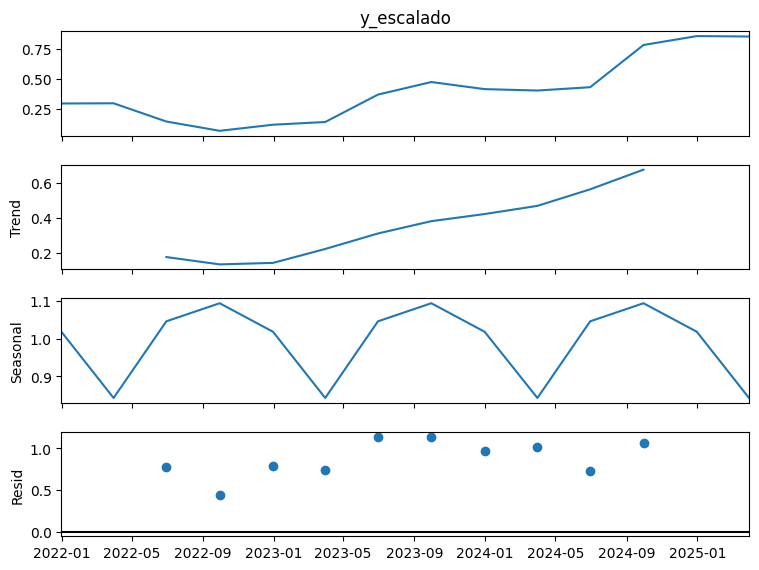

In [76]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

------------------------------------------------------------------------

* La descomposición conserva la misma estructura que con datos originales: tendencia creciente, estacionalidad que se repite cada 4 trimestres (factor entre 0.84 y 1.09) y residuos alrededor de 1.
* La amplitud estacional se ve mayor que en datos originales (±10-15% vs ±3%). Esto es un efecto del escalamiento: al restar el mínimo, los valores cercanos a 0 hacen que las variaciones relativas parezcan más grandes. No es una estacionalidad más fuerte en realidad.
* Por esta razón, la descomposición multiplicativa es más fiable con los datos originales.

--------------------------------------------------------------------------

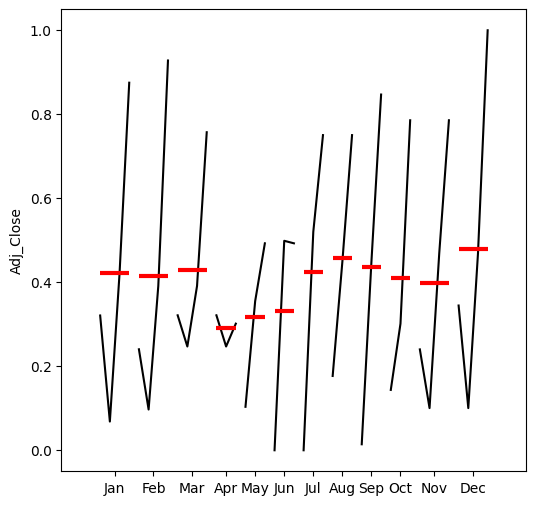

In [77]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

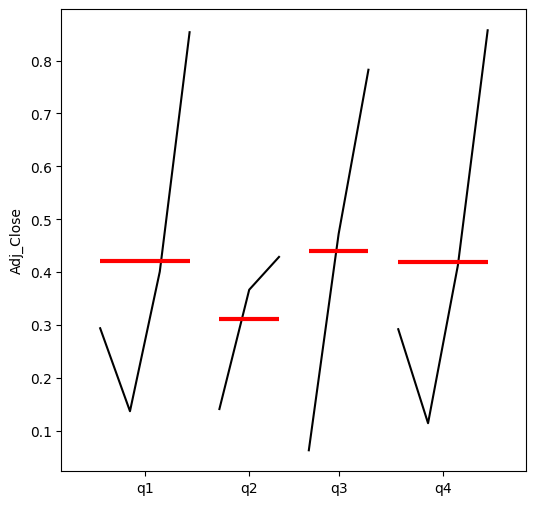

In [78]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

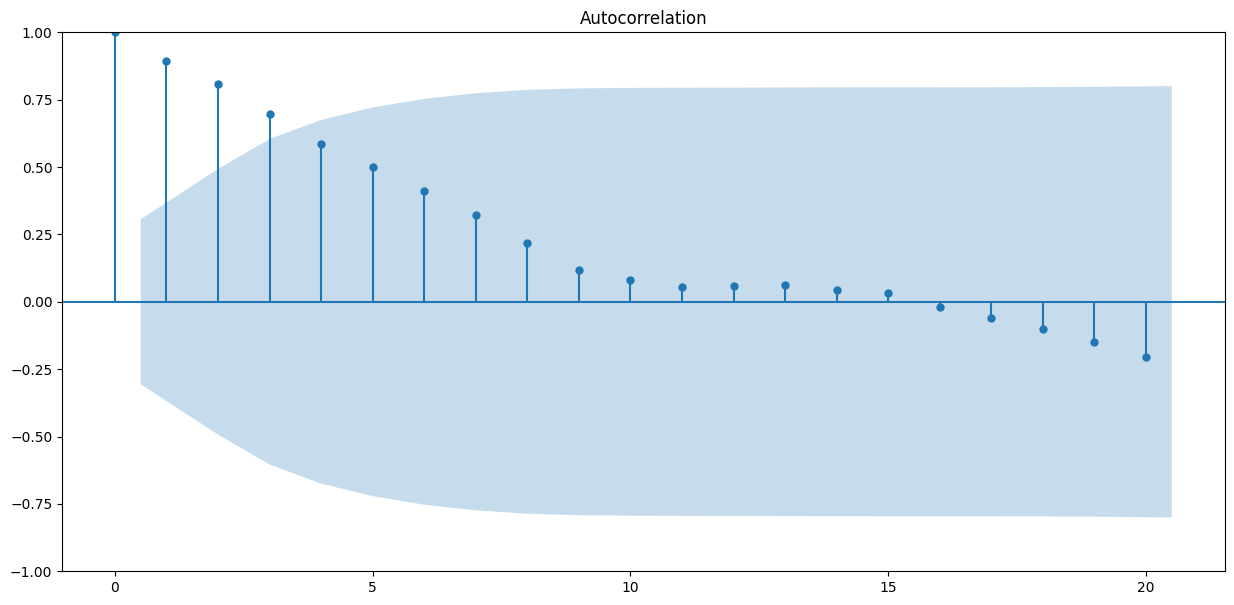

In [79]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
# Ajustamos lags a 20 ya que nuestro set de entrenamiento cuenta únicamente con 41 observaciones
plot_acf(train_escalado2['y_escalado'], lags = 20, ax=ax)
plt.show()

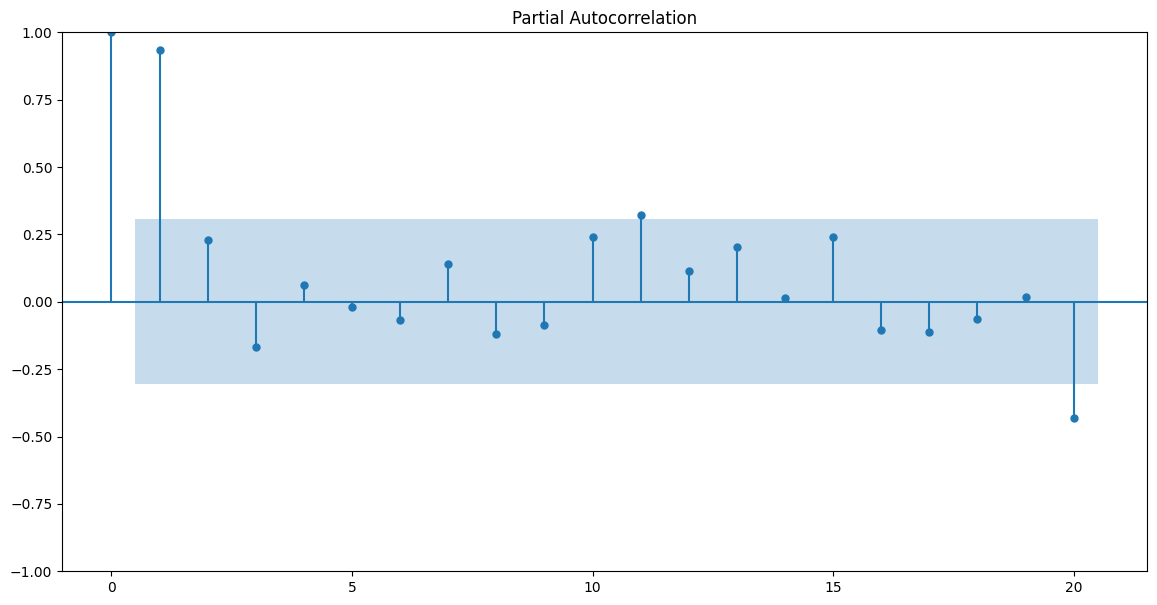

In [80]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 20, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [81]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real = 0.674, Predicción = 0.642


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real = 0.674, Predicción = 0.801


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real = 0.613, Predicción = 0.661
>Esperado-real = 0.633, Predicción = 0.820
>Esperado-real = 0.633, Predicción = 0.691
>Esperado-real = 1.044, Predicción = 0.736
>Esperado-real = 1.181, Predicción = 0.971
>Esperado-real = 1.181, Predicción = 1.276
>Esperado-real = 1.196, Predicción = 1.377
>Esperado-real = 1.196, Predicción = 1.022
>Esperado-real = 1.196, Predicción = 1.214
>Esperado-real = 1.041, Predicción = 1.003
>Esperado-real = 1.194, Predicción = 0.883
>Esperado-real = 1.194, Predicción = 1.108
>Esperado-real = 1.353, Predicción = 1.059
>Esperado-real = 1.523, Predicción = 1.203
>Esperado-real = 1.595, Predicción = 1.447
>Esperado-real = 1.736, Predicción = 1.921
>Esperado-real = 1.736, Predicción = 1.740
>Esperado-real = 1.736, Predicción = 1.607

Error-Modelo-ARIMA: RMSE: 0.178


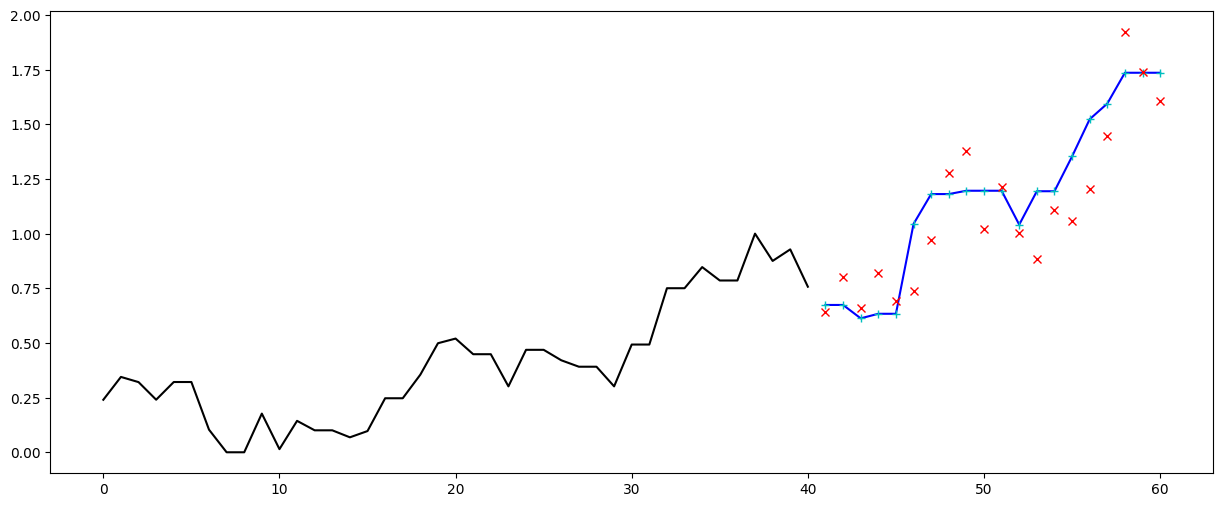

In [82]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------

* Las predicciones escaladas siguen la serie real con la misma forma y los mismos desaciertos que con datos originales (fallas en los cambios bruscos).
* RMSE escalado **0.178** (20.4 USD al convertirlo) frente a **21.216** con datos originales: son valores muy similares. La pequeña diferencia se debe a que en el modelo escalado se usó otro orden (1,0,5) en lugar de (1,0,13).
* Igual que antes, ARIMA no supera al modelo ingenuo (0.128).

-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [83]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,Adj Close,y
0,2021-11-30,161.341568,161.341568
1,2021-12-31,173.317764,173.317764
2,2022-01-31,170.594589,170.594589
3,2022-02-28,161.371201,161.371201
4,2022-03-31,170.645737,170.645737


In [84]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,Adj Close,y
0,2021-11-30,161.341568,161.341568
1,2021-12-31,173.317764,173.317764
2,2022-01-31,170.594589,170.594589
3,2022-02-28,161.371201,161.371201
4,2022-03-31,170.645737,170.645737


In [85]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [86]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [87]:
train_escalado.head()

,ds,Adj Close,y
0,2021-11-30,161.341568,0.240190
1,2021-12-31,173.317764,0.344681
2,2022-01-31,170.594589,0.320921
3,2022-02-28,161.371201,0.240448
4,2022-03-31,170.645737,0.321367


In [88]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [89]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.573


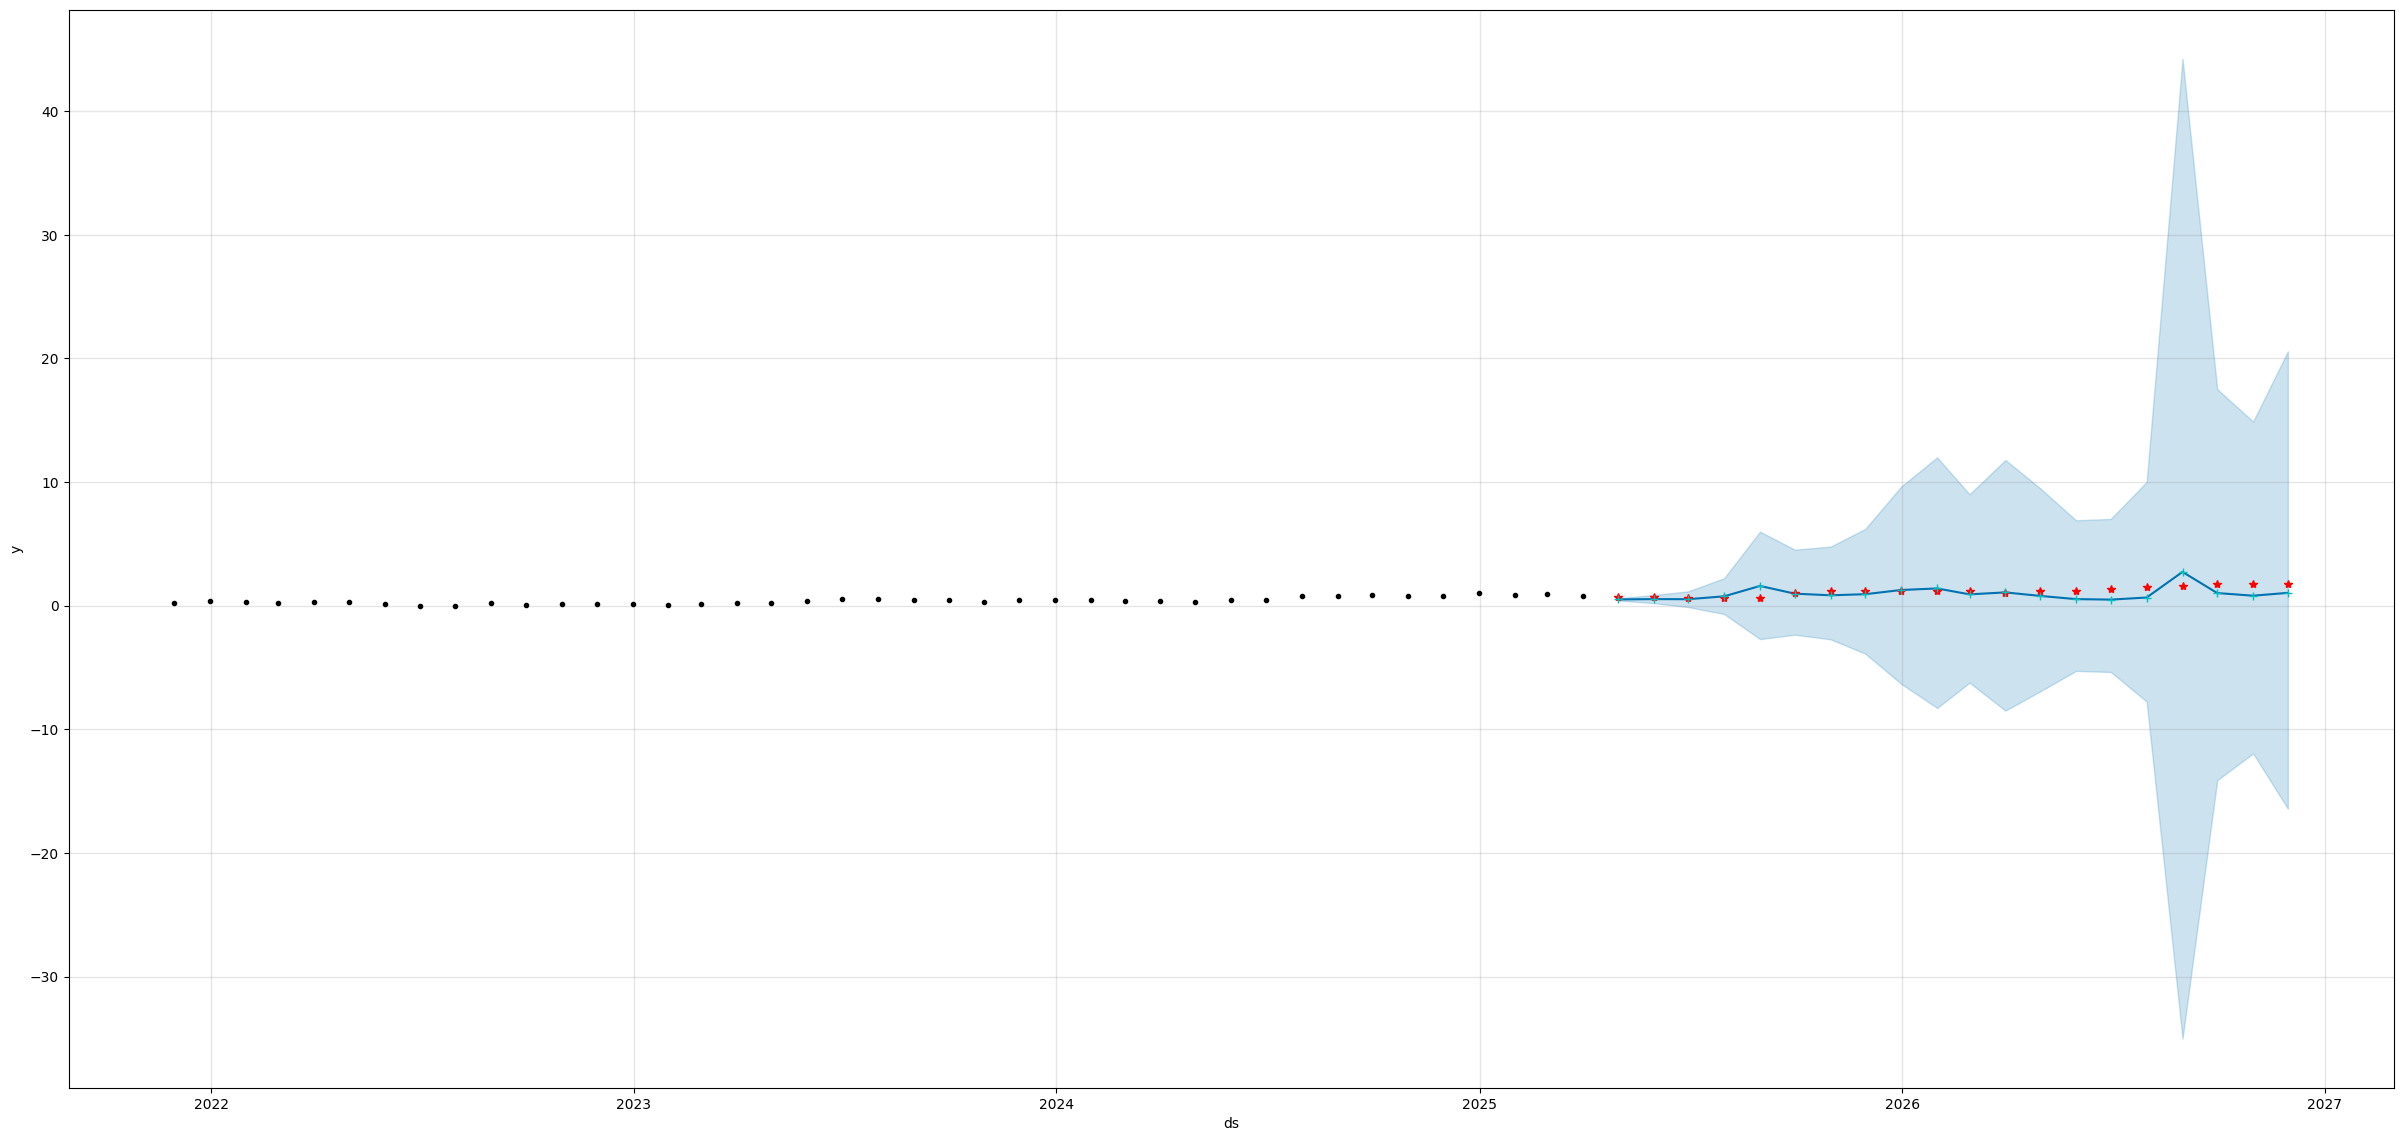

In [90]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en datos originales**

------------------------------------------------------------------------

* La predicción se mantiene aproximadamente plana y con un intervalo de incertidumbre que se abre mucho hacia el final (de -40 a +40 en escala), el mismo comportamiento inestable que con datos originales.
* RMSE escalado **0.573** (65.7 USD al convertirlo) frente a 266.677 con datos originales. Parece mejor, pero **Prophet** incorpora aleatoriedad en el ajuste y la configuración tan flexible hace que el resultado cambie mucho de una corrida a otra, por lo que la mejora no se atribuye con seguridad al escalamiento.
* Sigue siendo peor que el **modelo ingenuo y ARIMA**.

------------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [91]:
test_escalado.head()

,ds,Adj Close,y
41,2025-04-30,211.040619,0.673808
42,2025-05-31,211.040619,0.673808
43,2025-06-30,204.028137,0.612625
44,2025-07-31,206.414780,0.633448
45,2025-08-31,206.414780,0.633448


In [92]:
df_temp_escalado.head()

,ds,Adj Close,y
0,2021-11-30,161.341568,0.240190
1,2021-12-31,173.317764,0.344681
2,2022-01-31,170.594589,0.320921
3,2022-02-28,161.371201,0.240448
4,2022-03-31,170.645737,0.321367


In [93]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [94]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [95]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - loss: 0.1176 - root_mean_squared_error: 0.3429 - val_loss: 0.1737 - val_root_mean_squared_error: 0.4167 - learning_rate: 0.0500
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - loss: 8.4315 - root_mean_squared_error: 2.9037 - val_loss: 2.8044 - val_root_mean_squared_error: 1.6746 - learning_rate: 0.0500
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - loss: 1.7746 - root_mean_squared_error: 1.3321 - val_loss: 3.5980 - val_root_mean_squared_error: 1.8968 - learning_rate: 0.0500
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - loss: 8.7748 - root_mean_squared_error: 2.9622 - val_loss: 1.6103 - val_root_mean_squared_error: 1.2690 - learning_rate: 0.0500
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - loss: 1.4681 - root_mean_squared_error: 1.2117 - val_loss: 0.6002 - val_root_mean_squared_error: 0.7747 - learning_rate: 0.0500
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - loss: 0.6717 - root_mean_squared_error: 0.819

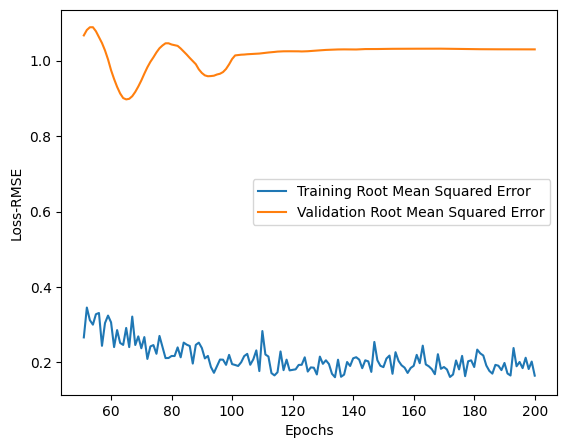

In [96]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [97]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step


(144,)

In [98]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 1.001


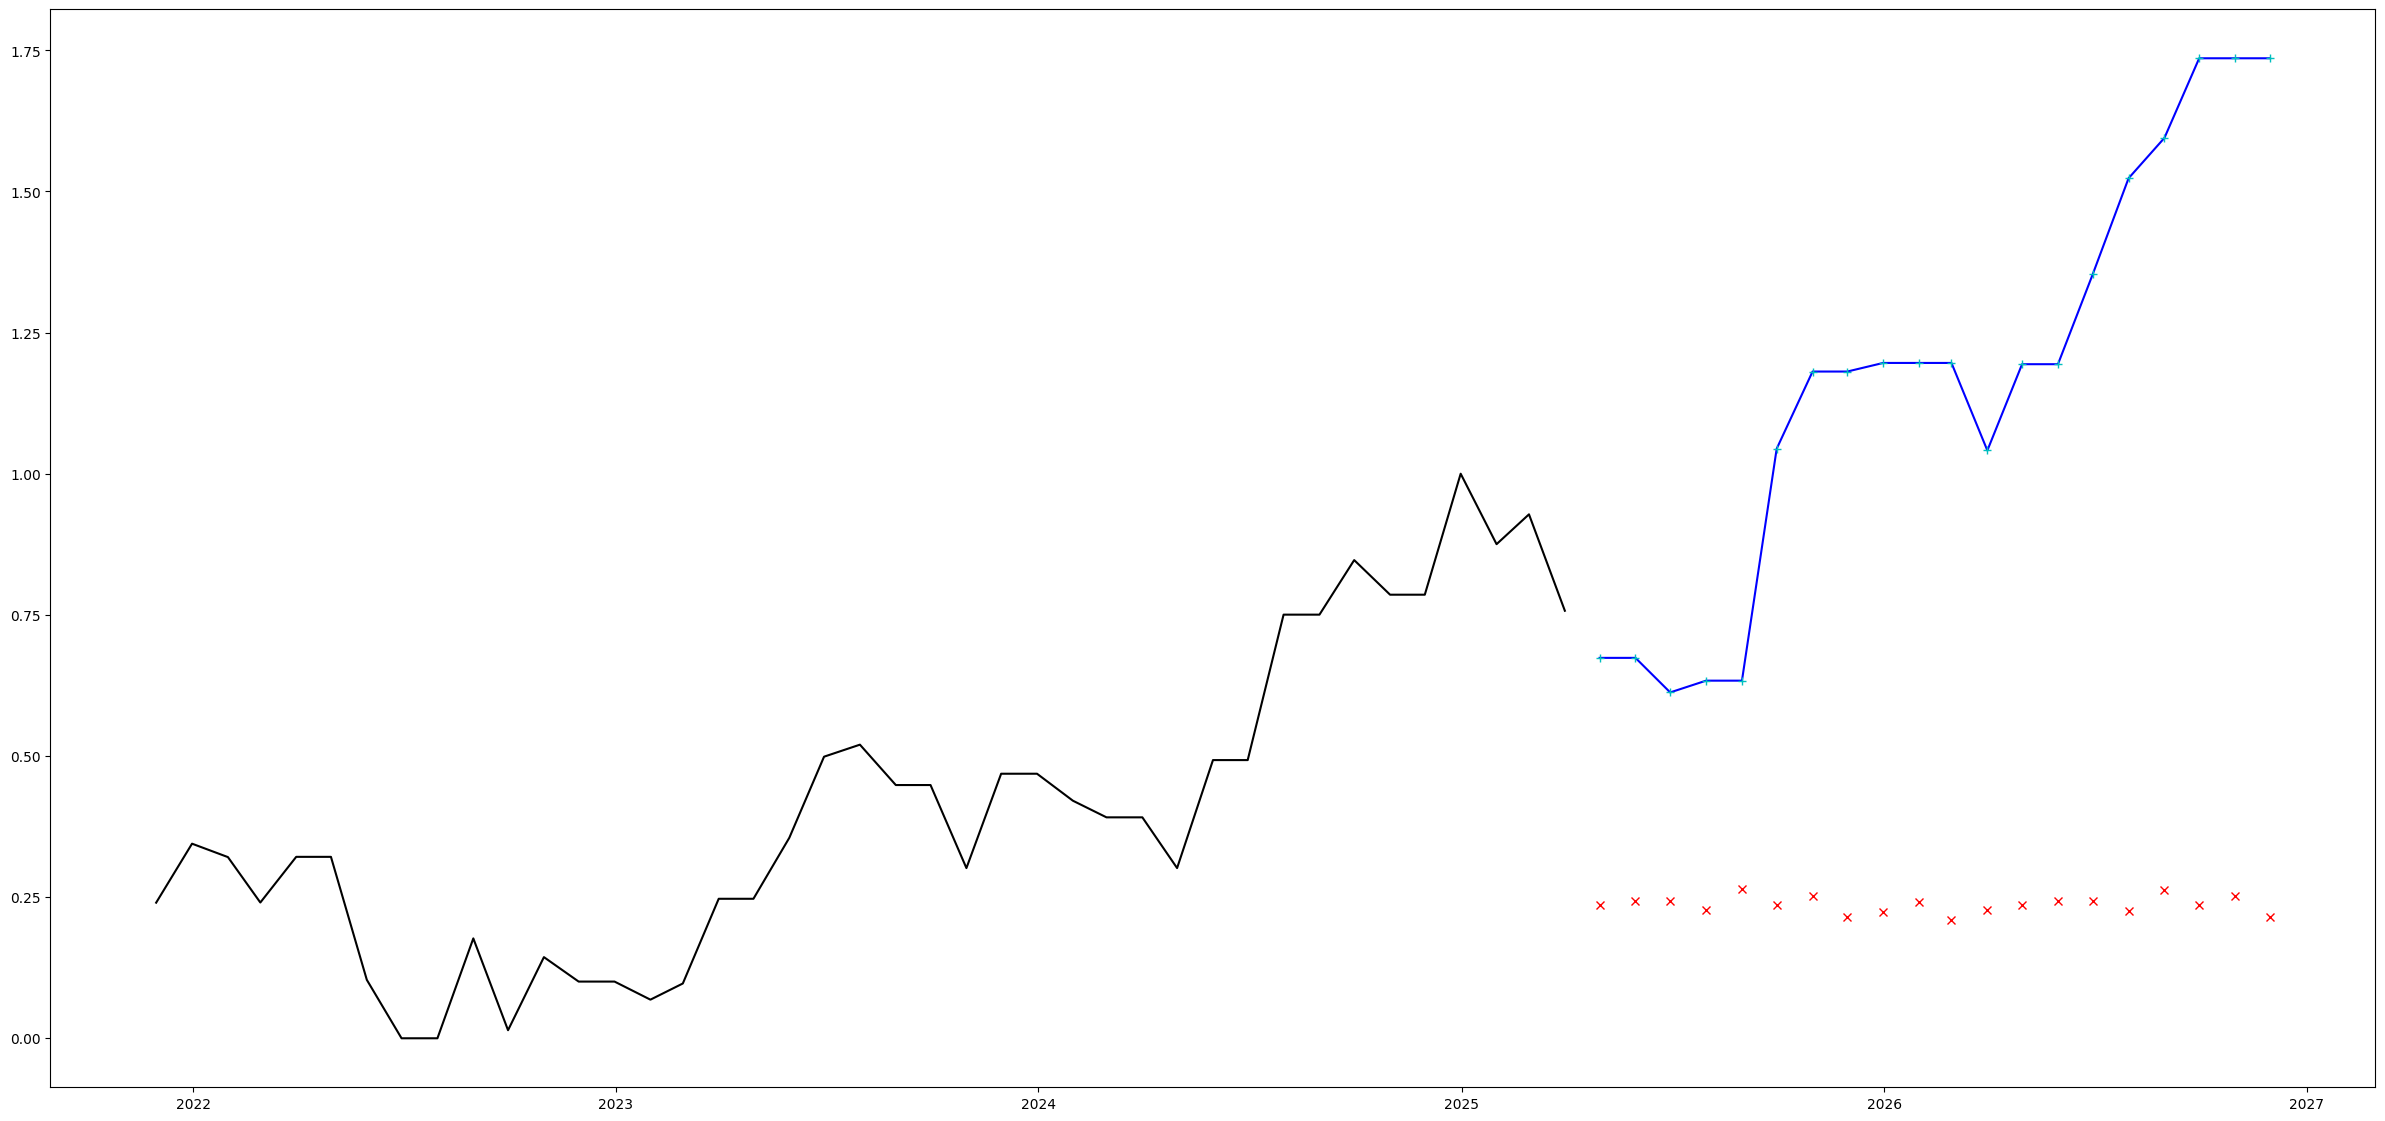

In [99]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------

* Se repite el problema: las predicciones (x rojas) forman una línea casi horizontal en 0.2, mientras que los valores reales suben hasta 1.74.
* La curva de aprendizaje muestra el RMSE de entrenamiento en 0.12-0.15 y el de validación en 1.05: sobreajuste claro.
* RMSE escalado **1.030** (118 USD al convertirlo), peor que el LSTM con datos originales (83.767). Aquí el escalamiento no ayudó, aunque la arquitectura (200 neuronas, dropout 0.4) y la fecha de corte también cambiaron respecto a la versión original.
* Se necesita una serie más larga (por ejemplo, datos diarios) para que el LSTM funcione.

-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

En general no, por lo menos en esta actividad. El escalamiento MinMax es una transformación lineal: cambia las unidades pero no la información de la serie. Sirve sobre todo para que los modelos de redes neuronales entrenen de forma más estable. Los RMSE no son comparables directamente (unos están en dólares y otros en escala 0-1), para compararlos hay que multiplicar el RMSE escalado por el rango del entrenamiento (114.6 USD).

### **Modelo Ingenuo**
Sin cambio: 14.622 USD contra 0.128 × 114.6 = 14.7 USD. El modelo solo repite el último valor, por lo que el escalamiento no tiene efecto.

### **Modelo ARIMA**
Resultado equivalente: 21.216 contra 0.178 × 114.6 = 20.4 USD. ARIMA es lineal y no depende de la escala, la pequeña diferencia viene del orden elegido (1,0,13) frente a (1,0,5).

### **Modelo Facebook-Meta-Prophet**
Aparente mejora: 266.677 contra 0.573 × 114.6 = 65.7 USD. Es el modelo más inestable con pocos datos y esta diferencia probablemente se debe a la sensibilidad del ajuste con parámetros tan flexibles y no a una ventaja real del escalamiento.

### **Modelo Long Short Term Memory (LSTM)**
Aquí es donde el escalamiento debería ayudar más, pero no lo hizo: 83.767 contra 1.030 × 114.6 = 118 USD. Con solo 41 datos mensuales la red sobreajusta y extrapola mal fuera del rango de entrenamiento (la acción superó su máximo previo), con o sin escalamiento.

A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 14.622 | 0.128 |
| 2 | Modelo ARIMA | 21.216 | 0.178 |
| 3 | Modelo Facebook-Meta-Prophet | 266.677 | 0.573 |
| 4 | Long Short Term Memory (LSTM) | 83.767 | 1.030 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

El orden de mejor a peor desempeño es: Ingenuo (14.622) < ARIMA (21.216) < LSTM (83.767) < Prophet (266.677). Los errores se expresan en dólares: el ingenuo se equivoca en promedio 15 USD y Prophet más de 250 USD.

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

El orden es: Ingenuo (0.128) < ARIMA (0.178) < Prophet (0.573) < LSTM (1.030). Los dos mejores modelos son los mismos que con datos originales. Prophet y LSTM intercambian posiciones, pero ambos quedan muy por encima del baseline. Un RMSE de 1.030 es alto porque el rango total de los datos escalados de entrenamiento es solo de 0 a 1.

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**

El escalamiento no mejora las predicciones por sí mismo, no modifica la información de la serie y el ranking de los dos mejores modelos se mantiene (ingenuo y ARIMA). Su utilidad principal es facilitar el entrenamiento de redes neuronales.
El modelo ingenuo fue el mejor en ambos escenarios, ningún modelo complejo lo superó. Una serie con tendencia fuerte y solo 41 datos de entrenamiento favorece a los modelos simples.
Prophet y LSTM sobreajustaron por la poca cantidad de datos mensuales (61 en total), necesitarían más observaciones (por ejemplo, datos diarios) o una configuración más sencilla.

Limitaciones: los últimos 20 meses de prueba están en un rango de precios que no se vió en el entrenamiento y los modelos se corrieron una sola vez, sin repeticiones (sobre todo Prophet y LSTM son variables entre corridas). Aun así, ARIMA es una opción razonable si se quiere un modelo más allá del baseline.

------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**